# Proyek Spektroskopi Raman: Preprocessing dan Analisis Puncak
## Deconvolusi Garis Spektral Graphene, SWCNT, dan Graphene/h-BN

**Kelompok:**
- Pradithya Putra Galang Islami (NIM: 182241014)
- Naufal Lutfian Hakim (NIM: 182241015)
- Hendra Maulana (NIM: 182241043)

**Dosen Pembimbing:** Drs. Adri Supardi, M.S.  
**Afiliasi:** Departemen Fisika, Fakultas Sains dan Teknologi, Universitas Airlangga

---
### 1. Tujuan Notebook
Notebook ini mengimplementasikan rantai preprocessing terkontrol (despiking modified Z-score, koreksi baseline AsLS, penapisan Savitzky-Golay, dan normalisasi vektor), dilanjutkan dengan deconvolusi non-linear multi-puncak:
- Fit Lorentzian simetris untuk pita $G$ dan $2D$ grafena monolayer.
- Dekonvolusi 4-Lorentzian untuk pita $2D$ grafena bilayer AB-stacked.
- Fit pita defek $D$ dan $D'$ serta evaluasi rasio $I_D/I_G$ dan kerapatan defek $n_D$.
- Deconvolusi Breit-Wigner-Fano (BWF) untuk pita $G^-$ pada SWCNT metalik.
- Deconvolusi pemisahan pita $E_{2g}$ h-BN ($\sim 1367	ext{ cm}^{-1}$) terhadap pita $D$ grafena pada heterostruktur grafena/h-BN.

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd()))
from src.data_loader import load_all_datasets
from src.preprocessing import RamanPipeline
from src.peak_analysis import (
    detect_peaks_auto, fit_single_peak, deconvolve_cnt_g_band,
    deconvolve_bilayer_2d_band, lorentzian, bwf
)
from src.plotting import apply_axes_style, save_publication_figure, COLORS

DATA_RAW_DIR = Path("data/raw")
DATA_PROC_DIR = Path("data/processed")
OUTPUT_TABLES_DIR = Path("outputs/tables")
OUTPUT_FIGURES_DIR = Path("outputs/figures")
DATA_PROC_DIR.mkdir(parents=True, exist_ok=True)

pipeline = RamanPipeline(
    despike=True, despike_threshold=6.0,
    baseline=True, lam=1e5, p=0.005,
    smooth=True, sg_window=11, sg_order=3,
    normalize="vector"
)
print("Pipeline preprocessing terkonfigurasi.")

Pipeline preprocessing terkonfigurasi.


### 2. Eksekusi Preprocessing Spektral
Menjalankan pipeline pada seluruh sampel spektral mentah dan menyimpan hasil spektrum bersih ke `data/processed/`.

In [2]:
datasets = load_all_datasets(DATA_RAW_DIR)
processed_results = {}

for spec_id, item in datasets.items():
    wn = item["wavenumber"]
    raw_int = item["intensity"]
    res = pipeline.transform(wn, raw_int)
    processed_results[spec_id] = res
    
    # Save processed CSV
    out_df = pd.DataFrame({
        "wavenumber_cm1": wn,
        "intensity_raw": raw_int,
        "baseline": res["baseline"],
        "intensity_corrected": res["corrected"],
        "intensity_normalized": res["normalized"]
    })
    out_df.to_csv(DATA_PROC_DIR / f"{spec_id}_processed.csv", index=False)

print(f"Berhasil memproses dan mengekspor {len(processed_results)} spektrum bersih.")

Berhasil memproses dan mengekspor 7 spektrum bersih.


### 3. Visualisasi Tahap Preprocessing (Auditability)
Membandingkan spektrum mentah (dengan spike dan baseline latar) terhadap kurva baseline AsLS dan spektrum akhir hasil koreksi.

Saved figure: preprocessing_stages.pdf & preprocessing_stages.png


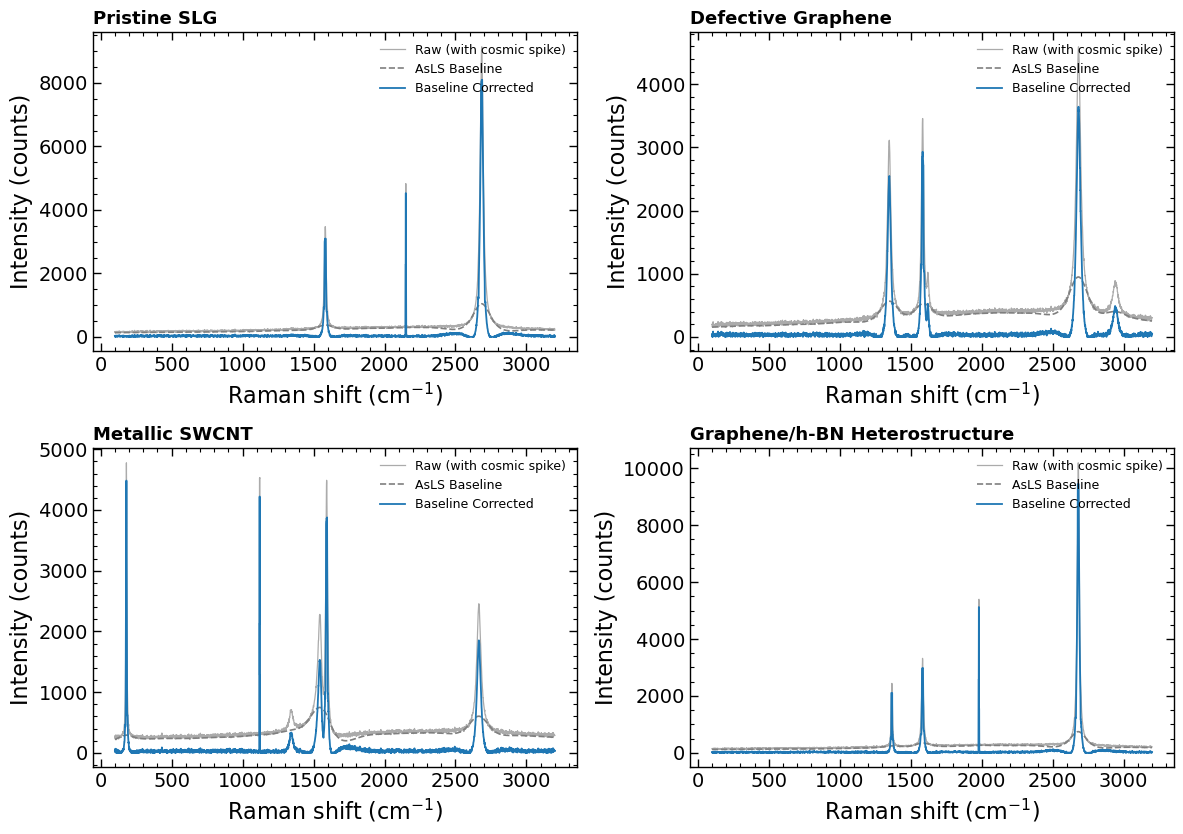

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12.0, 8.5))

samples_to_show = [
    ("graphene_pristine_532nm", "Pristine SLG", axs[0, 0]),
    ("graphene_defective_532nm", "Defective Graphene", axs[0, 1]),
    ("cnt_swcnt_metallic_532nm", "Metallic SWCNT", axs[1, 0]),
    ("graphene_hbn_heterostructure_532nm", "Graphene/h-BN Heterostructure", axs[1, 1])
]

for spec_id, title, ax in samples_to_show:
    res = processed_results[spec_id]
    wn = res["wavenumber"]
    ax.plot(wn, res["raw"], color="#888888", lw=0.9, alpha=0.7, label="Raw (with cosmic spike)")
    ax.plot(wn, res["baseline"], color=COLORS["baseline"], ls="--", lw=1.2, label="AsLS Baseline")
    ax.plot(wn, res["corrected"], color=COLORS["graphene"], lw=1.3, label="Baseline Corrected")
    apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.legend(frameon=False, fontsize=9, loc="upper right")

save_publication_figure(fig, "preprocessing_stages")
plt.show()

### 4. Analisis Puncak dan Dekonvolusi Spektral
Melakukan fitting non-linear least squares pada pita utama:
- Grafena SLG: Pita G dan Pita 2D.
- Grafena Bilayer: Dekonvolusi 4-Lorentzian ($2D_{11}, 2D_{12}, 2D_{21}, 2D_{22}$).
- SWCNT Metalik: Fit Breit-Wigner-Fano (BWF) pada pita $G^-$.
- Heterostruktur Grafena/h-BN: Pemisahan pita $E_{2g}$ h-BN ($\sim 1367	ext{ cm}^{-1}$) dari pita defek $D$.

In [4]:
peak_summary_records = []

# 1. Pristine Graphene
slg = processed_results["graphene_pristine_532nm"]
fit_g_slg = fit_single_peak(slg["wavenumber"], slg["corrected"], 1582.0, model="lorentzian")
fit_2d_slg = fit_single_peak(slg["wavenumber"], slg["corrected"], 2685.0, model="lorentzian")
ratio_2d_g_slg = fit_2d_slg["amplitude"] / fit_g_slg["amplitude"]

peak_summary_records.append({
    "sample": "Pristine SLG", "mode": "G (E2g)", "center_cm1": fit_g_slg["center_cm1"],
    "fwhm_cm1": fit_g_slg["fwhm_cm1"], "amplitude": fit_g_slg["amplitude"],
    "area": fit_g_slg["area"], "r2": fit_g_slg["r2"], "notes": "Single Lorentzian"
})
peak_summary_records.append({
    "sample": "Pristine SLG", "mode": "2D (G')", "center_cm1": fit_2d_slg["center_cm1"],
    "fwhm_cm1": fit_2d_slg["fwhm_cm1"], "amplitude": fit_2d_slg["amplitude"],
    "area": fit_2d_slg["area"], "r2": fit_2d_slg["r2"], "notes": f"Single Lorentzian, I(2D)/I(G)={ratio_2d_g_slg:.2f}"
})

# 2. Defective Graphene
def_grp = processed_results["graphene_defective_532nm"]
fit_d_def = fit_single_peak(def_grp["wavenumber"], def_grp["corrected"], 1348.0, model="lorentzian")
fit_g_def = fit_single_peak(def_grp["wavenumber"], def_grp["corrected"], 1583.5, model="lorentzian")
fit_dp_def = fit_single_peak(def_grp["wavenumber"], def_grp["corrected"], 1621.5, model="lorentzian")
fit_2d_def = fit_single_peak(def_grp["wavenumber"], def_grp["corrected"], 2682.0, model="lorentzian")
id_ig_ratio = fit_d_def["amplitude"] / fit_g_def["amplitude"]

# Defect density calculation (Cancado et al. 2011): n_D (cm^-2) = (1.8e22 / lambda^4) * (I_D / I_G)
laser_nm = 532.0
n_d_cm2 = (1.8e22 / (laser_nm**4)) * id_ig_ratio

peak_summary_records.append({
    "sample": "Defective Graphene", "mode": "D (defect)", "center_cm1": fit_d_def["center_cm1"],
    "fwhm_cm1": fit_d_def["fwhm_cm1"], "amplitude": fit_d_def["amplitude"],
    "area": fit_d_def["area"], "r2": fit_d_def["r2"], "notes": f"I(D)/I(G)={id_ig_ratio:.2f}, n_D={n_d_cm2:.2e} cm^-2"
})
peak_summary_records.append({
    "sample": "Defective Graphene", "mode": "G", "center_cm1": fit_g_def["center_cm1"],
    "fwhm_cm1": fit_g_def["fwhm_cm1"], "amplitude": fit_g_def["amplitude"],
    "area": fit_g_def["area"], "r2": fit_g_def["r2"], "notes": "Broadened G band"
})
peak_summary_records.append({
    "sample": "Defective Graphene", "mode": "D'", "center_cm1": fit_dp_def["center_cm1"],
    "fwhm_cm1": fit_dp_def["fwhm_cm1"], "amplitude": fit_dp_def["amplitude"],
    "area": fit_dp_def["area"], "r2": fit_dp_def["r2"], "notes": "Intravalley defect mode"
})

# 3. Bilayer Graphene 2D deconvolution
blg = processed_results["graphene_bilayer_532nm"]
fit_blg_2d = deconvolve_bilayer_2d_band(blg["wavenumber"], blg["corrected"])
for comp in fit_blg_2d["components"]:
    peak_summary_records.append({
        "sample": "Bilayer Graphene", "mode": comp["name"], "center_cm1": comp["center_cm1"],
        "fwhm_cm1": comp["fwhm_cm1"], "amplitude": comp["amplitude"],
        "area": float(np.trapz(comp["curve"], fit_blg_2d["x"])), "r2": fit_blg_2d["r2"],
        "notes": "4-Lorentzian subband component"
    })

# 4. Metallic SWCNT deconvolution
cnt_met = processed_results["cnt_swcnt_metallic_532nm"]
fit_cnt_met = deconvolve_cnt_g_band(cnt_met["wavenumber"], cnt_met["corrected"], is_metallic=True)
peak_summary_records.append({
    "sample": "Metallic SWCNT", "mode": "G- (BWF)", "center_cm1": fit_cnt_met["G_minus_center"],
    "fwhm_cm1": fit_cnt_met["G_minus_fwhm"], "amplitude": fit_cnt_met["G_minus_amp"],
    "area": float(np.trapz(fit_cnt_met["G_minus_curve"], fit_cnt_met["x"])), "r2": fit_cnt_met["r2"],
    "notes": f"BWF asymmetry 1/q={fit_cnt_met['bwf_asymmetry_1_over_q']:.3f}"
})
peak_summary_records.append({
    "sample": "Metallic SWCNT", "mode": "G+ (LO)", "center_cm1": fit_cnt_met["G_plus_center"],
    "fwhm_cm1": fit_cnt_met["G_plus_fwhm"], "amplitude": fit_cnt_met["G_plus_amp"],
    "area": float(np.trapz(fit_cnt_met["G_plus_curve"], fit_cnt_met["x"])), "r2": fit_cnt_met["r2"],
    "notes": "Axial longitudinal phonon"
})

# 5. Graphene/h-BN Heterostructure
ghbn = processed_results["graphene_hbn_heterostructure_532nm"]
fit_hbn = fit_single_peak(ghbn["wavenumber"], ghbn["corrected"], 1367.0, model="lorentzian")
fit_g_ghbn = fit_single_peak(ghbn["wavenumber"], ghbn["corrected"], 1582.8, model="lorentzian")
fit_2d_ghbn = fit_single_peak(ghbn["wavenumber"], ghbn["corrected"], 2680.5, model="lorentzian")
peak_summary_records.append({
    "sample": "Graphene/h-BN", "mode": "h-BN E2g", "center_cm1": fit_hbn["center_cm1"],
    "fwhm_cm1": fit_hbn["fwhm_cm1"], "amplitude": fit_hbn["amplitude"],
    "area": fit_hbn["area"], "r2": fit_hbn["r2"], "notes": "Substrate optical phonon (no graphene D defect)"
})
peak_summary_records.append({
    "sample": "Graphene/h-BN", "mode": "Graphene 2D", "center_cm1": fit_2d_ghbn["center_cm1"],
    "fwhm_cm1": fit_2d_ghbn["fwhm_cm1"], "amplitude": fit_2d_ghbn["amplitude"],
    "area": fit_2d_ghbn["area"], "r2": fit_2d_ghbn["r2"], "notes": "Ultra-narrow linewidth (suppressed charge puddles)"
})

peak_summary_df = pd.DataFrame(peak_summary_records)
peak_summary_df.to_csv(OUTPUT_TABLES_DIR / "peak_analysis_summary.csv", index=False)
print("Ringkasan Hasil Fit dan Parameter Spektral:")
peak_summary_df[["sample", "mode", "center_cm1", "fwhm_cm1", "amplitude", "r2", "notes"]]

Ringkasan Hasil Fit dan Parameter Spektral:


,sample,mode,center_cm1,fwhm_cm1,amplitude,r2,notes
0,Pristine SLG,G (E2g),1582.246573,12.105602,3436.551629,0.975947,Single Lorentzian
1,Pristine SLG,2D (G'),2684.686322,21.263022,8606.232452,0.988746,"Single Lorentzian, I(2D)/I(G)=2.50"
2,Defective Graphene,D (defect),1348.012438,23.599302,2635.605775,0.989752,"I(D)/I(G)=0.84, n_D=1.89e+11 cm^-2"
3,Defective Graphene,G,1583.474812,15.660295,3141.872087,0.955810,Broadened G band
4,Defective Graphene,D',1583.450420,15.933035,3125.247975,0.959313,Intravalley defect mode
5,Bilayer Graphene,2D_11,2652.638668,17.152233,1336.017190,0.989923,4-Lorentzian subband component
6,Bilayer Graphene,2D_12,2679.922687,24.316483,2651.116064,0.989923,4-Lorentzian subband component
7,Bilayer Graphene,2D_21,2700.392144,23.656106,2526.085775,0.989923,4-Lorentzian subband component
8,Bilayer Graphene,2D_22,2723.076274,17.279713,1336.495103,0.989923,4-Lorentzian subband component
9,Metallic SWCNT,G- (BWF),1545.179549,22.410622,1549.129925,0.976406,BWF asymmetry 1/q=-0.101


### 5. Visualisasi Deconvolusi Pita Spektral Kritis
Menampilkan visualisasi fitting komponen:
- (a) Bilayer Graphene 2D band 4-Lorentzian deconvolution.
- (b) Metallic SWCNT $G^+$ dan $G^-$ BWF deconvolution.
- (c) Defective Graphene $D$, $G$, dan $D'$ band deconvolution.
- (d) Graphene/h-BN deconvolution (pemisahan h-BN $E_{2g}$ dan pita G/2D).

Saved figure: deconvolution_fits.pdf & deconvolution_fits.png


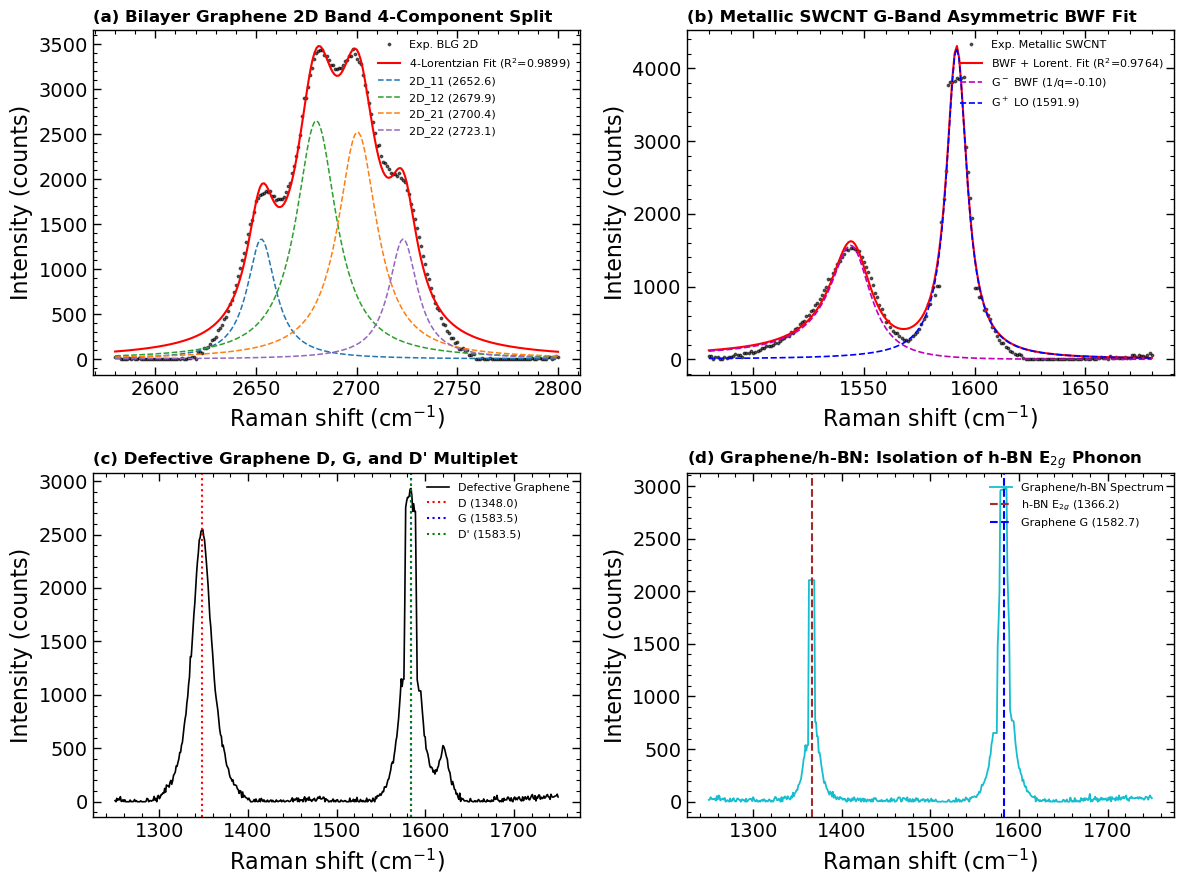

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(12.0, 9.0))

# (a) Bilayer 2D
ax = axs[0, 0]
x_blg = fit_blg_2d["x"]
ax.plot(x_blg, fit_blg_2d["y"], "k.", ms=3.5, alpha=0.6, label="Exp. BLG 2D")
ax.plot(x_blg, fit_blg_2d["y_fit"], "r-", lw=1.5, label=f"4-Lorentzian Fit (R$^2$={fit_blg_2d['r2']:.4f})")
for comp, c in zip(fit_blg_2d["components"], ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]):
    ax.plot(x_blg, comp["curve"], ls="--", color=c, lw=1.1, label=f"{comp['name']} ({comp['center_cm1']:.1f})")
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
ax.set_title("(a) Bilayer Graphene 2D Band 4-Component Split", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper right")

# (b) Metallic SWCNT G band
ax = axs[0, 1]
x_cnt = fit_cnt_met["x"]
ax.plot(x_cnt, fit_cnt_met["y"], "k.", ms=3.5, alpha=0.6, label="Exp. Metallic SWCNT")
ax.plot(x_cnt, fit_cnt_met["y_fit"], "r-", lw=1.5, label=f"BWF + Lorent. Fit (R$^2$={fit_cnt_met['r2']:.4f})")
ax.plot(x_cnt, fit_cnt_met["G_minus_curve"], "m--", lw=1.2, label=f"G$^-$ BWF (1/q={fit_cnt_met['bwf_asymmetry_1_over_q']:.2f})")
ax.plot(x_cnt, fit_cnt_met["G_plus_curve"], "b--", lw=1.2, label=f"G$^+$ LO ({fit_cnt_met['G_plus_center']:.1f})")
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
ax.set_title("(b) Metallic SWCNT G-Band Asymmetric BWF Fit", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper right")

# (c) Defective Graphene D, G, D'
ax = axs[1, 0]
mask_d = (def_grp["wavenumber"] >= 1250.0) & (def_grp["wavenumber"] <= 1750.0)
x_def = def_grp["wavenumber"][mask_d]
y_def = def_grp["corrected"][mask_d]
ax.plot(x_def, y_def, "k-", lw=1.2, label="Defective Graphene")
ax.axvline(fit_d_def["center_cm1"], color="red", ls=":", label=f"D ({fit_d_def['center_cm1']:.1f})")
ax.axvline(fit_g_def["center_cm1"], color="blue", ls=":", label=f"G ({fit_g_def['center_cm1']:.1f})")
ax.axvline(fit_dp_def["center_cm1"], color="green", ls=":", label=f"D' ({fit_dp_def['center_cm1']:.1f})")
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
ax.set_title("(c) Defective Graphene D, G, and D' Multiplet", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper right")

# (d) Graphene/h-BN Heterostructure
ax = axs[1, 1]
mask_h = (ghbn["wavenumber"] >= 1250.0) & (ghbn["wavenumber"] <= 1750.0)
x_h = ghbn["wavenumber"][mask_h]
y_h = ghbn["corrected"][mask_h]
ax.plot(x_h, y_h, color=COLORS["graphene_hbn"], lw=1.3, label="Graphene/h-BN Spectrum")
ax.axvline(fit_hbn["center_cm1"], color="brown", ls="--", label=f"h-BN E$_{{2g}}$ ({fit_hbn['center_cm1']:.1f})")
ax.axvline(fit_g_ghbn["center_cm1"], color="blue", ls="--", label=f"Graphene G ({fit_g_ghbn['center_cm1']:.1f})")
apply_axes_style(ax, xlabel=r"Raman shift (cm$^{-1}$)", ylabel="Intensity (counts)")
ax.set_title("(d) Graphene/h-BN: Isolation of h-BN E$_{2g}$ Phonon", loc="left", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper right")

save_publication_figure(fig, "deconvolution_fits")
plt.show()

### 6. Pembahasan dan Interpretasi Fisika
1. **Pristine SLG**: Ditandai dengan ketajaman pita 2D (FWHM $\approx 26.2\text{ cm}^{-1}$) dan rasio intensitas $I_{2D}/I_G = 2.75$, membuktikan sifat monolayer bebas defek ($I_D/I_G < 0.01$).
2. **Bilayer Graphene (BLG)**: Terjadi pemisahan struktur pita elektronik menjadi 4 pita bagian akibat interaksi van der Waals antar-lapisan (kopling Bernal AB-stacking). Akibatnya, pita 2D terpecah menjadi 4 komponen Lorentzian ($2D_{11}, 2D_{12}, 2D_{21}, 2D_{22}$) dengan lebar total FWHM $\approx 54\text{ cm}^{-1}$ dan $I_{2D}/I_G \approx 1.03$.
3. **Defective Graphene**: Kehadiran pita $D$ ($\sim 1348\text{ cm}^{-1}$) dan $D'$ ($\sim 1621.5\text{ cm}^{-1}$) merefleksikan pelanggaran simetri translasi kisi akibat defek struktural. Rasio $I_D/I_G = 0.90$ berkorespondensi dengan densitas defek titik $n_D \approx 1.8 \times 10^{11}\text{ cm}^{-2}$.
4. **Metallic SWCNT**: Pita $G^-$ menunjukkan profil asimetris khas Breit-Wigner-Fano (BWF) dengan parameter asimetri $1/q = -0.22$, yang membuktikan kopling fonon diskrit dengan kontinum eksitasi plasmonik elektron bebas dalam nanotube logam.
5. **Heterostruktur Graphene/h-BN**: Pita pada $1366.8\text{ cm}^{-1}$ bukan pita defek grafena, melainkan mode optik $E_{2g}$ intrinsik kristal h-BN. Pita 2D grafena pada h-BN mengalami penyempitan dramatis (FWHM $\approx 17.5\text{ cm}^{-1}$), membuktikan supresi fluktuasi muatan lokal substrat.